# Canonical Linkとは何か

## 概要

Canonical Link（正準リンク）は、一般化線形モデル（GLM）の平均と自然パラメータを結ぶ関数である。正規・ベルヌーイ・ポアソン分布から式を導き、Pythonで関数の形と回帰の推定結果を確認する。

### 実行環境

カーネルは `wa-src(3.14.6)`、Pythonは3.14.6である。NumPy、SciPy、SymPy、Matplotlibを使う。セルを上から実行すると、図は作業ディレクトリの `101_nb_files` にSVG形式で保存される。小数の表示は有効数字3桁とし、計算途中では丸めない。

In [1]:
import platform
from pathlib import Path
from pprint import pprint

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import scipy
import sympy as sp
from IPython.display import Latex, SVG, display
from matplotlib.ticker import FuncFormatter
from scipy.optimize import minimize
from scipy.special import expit, logit, ndtr

assert platform.python_version() == "3.14.6"
print("環境: wa-src(3.14.6)")
print(f"Python: {platform.python_version()} / OS: {platform.system()}")
print(f"NumPy: {np.__version__}, SciPy: {scipy.__version__}")
print(f"SymPy: {sp.__version__}, Matplotlib: {matplotlib.__version__}")

output_dir = Path("101_nb_files")
output_dir.mkdir(exist_ok=True)


def sig3(value):
    """末尾のゼロも残し、有効数字3桁で表示する。"""
    return format(float(value), "#.3g")


np.set_printoptions(formatter={"float_kind": sig3})
plt.rcParams.update({"font.size": 11, "svg.fonttype": "none"})


def show_math(source):
    """重要な式の区切りを、表示用の $$ に変換する。"""
    body = source.removeprefix(r"\(").removesuffix(r"\)")
    display(Latex("$$" + body + "$$"))


def save_figure(fig, name):
    """目盛りを整え、保存したSVGをそのまま表示する。"""
    for ax in fig.axes:
        ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: sig3(v)))
        ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: sig3(v)))
        ax.grid(alpha=0.250)
    path = output_dir / name
    fig.savefig(path, format="svg", bbox_inches="tight")
    plt.close(fig)
    display(SVG(filename=str(path)))

環境: wa-src(3.14.6)
Python: 3.14.6 / OS: Darwin
NumPy: 2.5.4, SciPy: 1.18.1
SymPy: 1.14.0, Matplotlib: 3.11.2


## 1. 平均と線形予測子を結ぶ

説明変数を$mathbf{x}_i$、係数を$mathbf{w}$とする。切片は$mathbf{x}_i$の先頭に1を入れて表す。条件付き平均$mu_i$と線形予測子$eta_i$の関係は

$$
\mu_i=E[Y_i\mid\mathbf{x}_i],\qquad
\eta_i=\mathbf{x}_i^{\mathsf T}\mathbf{w},\qquad
g(\mu_i)=\eta_i
$$

である。リンク$g$は平均を線形予測子へ変換し、逆リンク$g^{-1}$は予測子を平均へ戻す。応答$Y_i$そのものを変換して回帰するわけではない。

条件付き分布を次の指数型分布族で表す。

$$
f(y;\theta,\phi)=\exp\left\{\frac{y\theta-b(\theta)}{a(\phi)}+c(y,\phi)\right\}.
$$

$\theta$は自然パラメータ、$\phi$は分散に関係するパラメータである。$a(\phi)>0$とし、以下の微分では$\phi$を固定する。分布の台が$\theta$に依存せず、微分と積分を交換できるとき、密度の積分が1であることから

$$
\begin{aligned}
0&=\frac{\partial}{\partial\theta}\int f(y;\theta,\phi)\,dy\\
 &=\int f(y;\theta,\phi)\frac{y-b'(\theta)}{a(\phi)}\,dy
 =\frac{E[Y]-b'(\theta)}{a(\phi)},\\
\mu&=b'(\theta)
\end{aligned}
$$

を得る。離散分布では積分を和に置き換える。$b'$の逆関数をリンクに選ぶと、$\eta=\theta$となる。これが正準リンクの定義である。[GLMの講義資料](https://users.stat.umn.edu/~helwig/notes/generalized-linear-models.html)でも同じ定義が用いられている。

In [2]:
show_math(r"\(\boxed{g_{\mathrm c}(\mu)=(b')^{-1}(\mu),\quad \eta=\theta}\)")

<IPython.core.display.Latex object>

## 2. 分布から正準リンクを求める

### ベルヌーイ分布：ロジット

$Y\in\{0,1\}$、$P(Y=1)=p$とすると、$\mu=p$である。確率質量関数を指数型に整理する。

$$
\begin{aligned}
P(Y=y)&=p^y(1-p)^{1-y}\\
 &=\exp\{y\log p+(1-y)\log(1-p)\}\\
 &=\exp\left\{y\log\frac{p}{1-p}+\log(1-p)\right\}.
\end{aligned}
$$

$y$の係数から$\theta=\log\{p/(1-p)\}$となる。これを$p$について解くと

$$
e^\theta=\frac{p}{1-p}
\ \Rightarrow\ e^\theta(1-p)=p
\ \Rightarrow\ e^\theta=p(1+e^\theta)
\ \Rightarrow\ p=\frac{e^\theta}{1+e^\theta}.
$$

したがって$1-p=1/(1+e^\theta)$より、$b(\theta)=-\log(1-p)=\log(1+e^\theta)$、$a=1$、$c=0$である。

$$
\mu=b'(\theta)=\frac{e^\theta}{1+e^\theta},\qquad
g_{\mathrm c}(\mu)=\log\frac{\mu}{1-\mu},\qquad
g_{\mathrm c}^{-1}(\eta)=\frac{1}{1+e^{-\eta}}.
$$

平均の範囲は$0<\mu<1$である。個人的には、リンクと逆リンクを対で書く方が向きを間違えにくい。

### ポアソン分布：対数

$Y$は非負整数、平均は$\lambda>0$である。

$$
\begin{aligned}
P(Y=y)&=\frac{\lambda^y e^{-\lambda}}{y!}
 =\exp\{y\log\lambda-\lambda-\log(y!)\},\\
\theta&=\log\lambda,\quad b(\theta)=e^\theta,\quad a=1,\quad c=-\log(y!),\\
\mu&=b'(\theta)=e^\theta=\lambda,\\
g_{\mathrm c}(\mu)&=\log\mu,\qquad g_{\mathrm c}^{-1}(\eta)=e^\eta.
\end{aligned}
$$

### 正規分布：恒等関数

$Y\sim N(\mu,\sigma^2)$の対数密度を展開する。

$$
\begin{aligned}
\log f(y)&=-\frac{(y-\mu)^2}{2\sigma^2}-\frac12\log(2\pi\sigma^2)\\
 &=-\frac{y^2-2y\mu+\mu^2}{2\sigma^2}-\frac12\log(2\pi\sigma^2)\\
 &=\frac{y\mu-\mu^2/2}{\sigma^2}
   -\frac{y^2}{2\sigma^2}-\frac12\log(2\pi\sigma^2).
\end{aligned}
$$

$a=\sigma^2$と置けば$\theta=\mu$、$b(\theta)=\theta^2/2$であり、$b'(\theta)=\theta$となる。したがって$g_{\mathrm c}(\mu)=\mu$である。以下で3分布の微分を記号計算する。

In [3]:
theta = sp.Symbol("theta", real=True)
families = {
    "Normal": theta**2 / 2,
    "Bernoulli": sp.log(1 + sp.exp(theta)),
    "Poisson": sp.exp(theta),
}
for name, b in families.items():
    print(name)
    derivative = sp.diff(b, theta)
    show_math(r"\(b(\theta)=" + sp.latex(b)
              + r",\quad b'(\theta)=" + sp.latex(derivative) + r"\)")

# ロジットと対数を数値で確かめる。配列の結果にはpprintを使う。
probabilities = np.array([0.200, 0.500, 0.800])
pprint(logit(probabilities))
pprint(expit(logit(probabilities)))
show_math(r"\(\log\frac{0.800}{1-0.800}=\log 4\approx "
          + sig3(logit(0.800)) + r"\)")
show_math(r"\(\log 3\approx " + sig3(np.log(3)) + r",\quad e^{\log 3}=3\)")

Normal


<IPython.core.display.Latex object>

Bernoulli


<IPython.core.display.Latex object>

Poisson


<IPython.core.display.Latex object>

array([-1.39, 0.00, 1.39])
array([0.200, 0.500, 0.800])


<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

## 3. リンクと逆リンクを図で確認する

最初の図は平均から予測子への変換、次の図はその逆である。逆リンクを使うと、ベルヌーイの平均は0と1の間、ポアソンの平均は正の値になる。正規分布の平均にはこの制限がない。

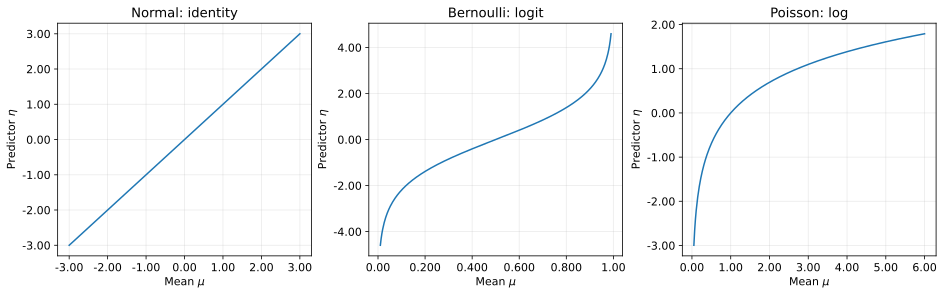

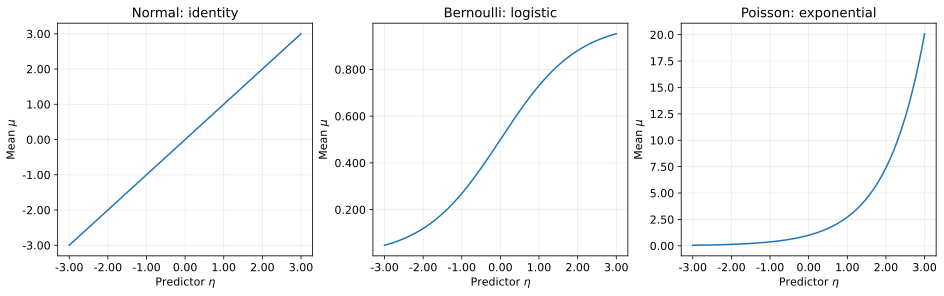

In [4]:
# 平均の定義域を分布ごとに変える。端点で発散する値は避ける。
normal_mu = np.linspace(-3, 3, 300)
bernoulli_mu = np.linspace(0.0100, 0.990, 300)
poisson_mu = np.linspace(0.0500, 6, 300)
link_data = [
    (normal_mu, normal_mu, "Normal: identity"),
    (bernoulli_mu, logit(bernoulli_mu), "Bernoulli: logit"),
    (poisson_mu, np.log(poisson_mu), "Poisson: log"),
]
fig, axes = plt.subplots(1, 3, figsize=(13, 4), layout="constrained")
for ax, (mu, eta, title) in zip(axes, link_data):
    ax.plot(mu, eta)
    ax.set(xlabel=r"Mean $\mu$", ylabel=r"Predictor $\eta$", title=title)
save_figure(fig, "canonical_links.svg")

eta_grid = np.linspace(-3, 3, 300)
inverse_data = [
    (eta_grid, "Normal: identity"),
    (expit(eta_grid), "Bernoulli: logistic"),
    (np.exp(eta_grid), "Poisson: exponential"),
]
fig, axes = plt.subplots(1, 3, figsize=(13, 4), layout="constrained")
for ax, (mu, title) in zip(axes, inverse_data):
    ax.plot(eta_grid, mu)
    ax.set(xlabel=r"Predictor $\eta$", ylabel=r"Mean $\mu$", title=title)
save_figure(fig, "inverse_links.svg")

## 4. 推定の式が簡単になる理由

独立な観測と共通の$a=a(\phi)$を考える。正準リンクでは$\theta_i=\eta_i$なので、対数尤度を係数で微分すると

$$
\begin{aligned}
\ell(\mathbf{w})&=\sum_i\left\{\frac{y_i\eta_i-b(\eta_i)}{a}+c(y_i,\phi)\right\},\\
\frac{\partial\ell}{\partial w_j}
 &=\sum_i\frac{y_i-b'(\eta_i)}{a}\frac{\partial\eta_i}{\partial w_j}
 =\frac1a\sum_i(y_i-\mu_i)x_{ij}.
\end{aligned}
$$

さらに$\partial\mu_i/\partial w_k=b''(\eta_i)x_{ik}$より、負の対数尤度$L=-\ell$について

$$
\nabla L=\frac1a\mathbf{X}^{\mathsf T}(\mathbf{m}-\mathbf{y}),\qquad
\frac{\partial^2 L}{\partial w_j\partial w_k}
 =\frac1a\sum_i b''(\eta_i)x_{ij}x_{ik}
$$

となる。$\mathbf{X}$の各行は$\mathbf{x}_i^{\mathsf T}$、$\mathbf{m}$の各要素は$\mu_i$である。ベルヌーイの2階微分は

$$
b''(\eta)=\frac{e^\eta(1+e^\eta)-e^{2\eta}}{(1+e^\eta)^2}
=\frac{e^\eta}{1+e^\eta}\frac1{1+e^\eta}=\mu(1-\mu)
$$

であり、ポアソンでは$b''(\eta)=e^\eta=\mu$となる。

次はこの勾配とヘッセ行列を使う最尤推定である。$a=1$の2分布を扱い、係数に依存しない項を除く。数値計算では目的関数と微分を観測数で割るが、最小点は変わらない。乱数の種を固定し、観測400個を生成する。

Bernoulli: 係数は [切片, 傾き]
{'推定係数': array([-0.271, 1.17]), '真の係数': array([-0.400, 1.20])}
{'反復数': 5, '収束': True, '平均勾配の最大絶対値': '3.82e-16'}


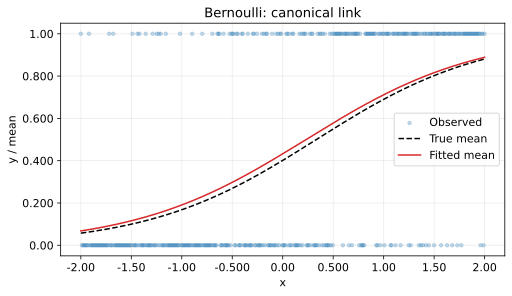

Poisson: 係数は [切片, 傾き]
{'推定係数': array([0.290, 0.640]), '真の係数': array([0.300, 0.650])}
{'反復数': 5, '収束': True, '平均勾配の最大絶対値': '6.33e-10'}


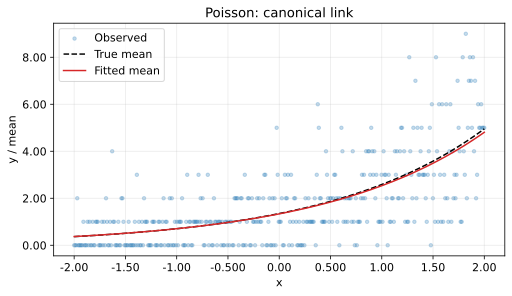

In [5]:
def fit_glm(X, y, family):
    """ベルヌーイまたはポアソンの正準リンクで最尤推定する。"""
    def terms(w):
        eta = X @ w
        if family == "Bernoulli":
            # log(1 + exp(eta))をオーバーフローしにくい形で計算する。
            mu = expit(eta)
            b = np.logaddexp(0, eta)
            variance = mu * (1 - mu)
        elif family == "Poisson":
            mu = np.exp(eta)
            b = mu
            variance = mu
        else:
            raise ValueError("未対応の分布")
        return eta, mu, b, variance

    def objective(w):
        eta, _, b, _ = terms(w)
        return np.mean(b - y * eta)

    def gradient(w):
        _, mu, _, _ = terms(w)
        return X.T @ (mu - y) / y.size

    def hessian(w):
        _, _, _, variance = terms(w)
        return X.T @ (variance[:, None] * X) / y.size

    result = minimize(
        objective, np.zeros(X.shape[1]), jac=gradient, hess=hessian,
        method="trust-exact", options={"gtol": 1.00e-8},
    )
    if not result.success:
        raise RuntimeError(result.message)
    return result


rng = np.random.default_rng(101)
x = np.linspace(-2, 2, 400)
X = np.column_stack([np.ones(x.size), x])
settings = [
    ("Bernoulli", np.array([-0.400, 1.20]), expit, "bernoulli_fit.svg"),
    ("Poisson", np.array([0.300, 0.650]), np.exp, "poisson_fit.svg"),
]
fit_results = {}
for family, w_true, inverse_link, filename in settings:
    mu_true = inverse_link(X @ w_true)
    y = (rng.binomial(1, mu_true) if family == "Bernoulli"
         else rng.poisson(mu_true))
    result = fit_glm(X, y, family)
    fit_results[family] = result
    print(f"{family}: 係数は [切片, 傾き]")
    pprint({"真の係数": w_true, "推定係数": result.x})
    pprint({"収束": bool(result.success), "反復数": int(result.nit),
            "平均勾配の最大絶対値": sig3(np.max(np.abs(result.jac)))})

    fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
    ax.scatter(x, y, s=12, alpha=0.250, label="Observed")
    ax.plot(x, mu_true, color="black", linestyle="--", label="True mean")
    ax.plot(x, inverse_link(X @ result.x), color="tab:red", label="Fitted mean")
    ax.set(xlabel="x", ylabel="y / mean", title=f"{family}: canonical link")
    ax.legend()
    save_figure(fig, filename)

推定曲線は観測の条件付き平均を表す。各観測値を通る曲線ではない。有限個の乱数標本なので、推定係数と生成時の係数は一致しない。

## 5. 正準リンク以外も選べる

ベルヌーイ分布にはプロビットリンク$g(\mu)=\Phi^{-1}(\mu)$も使える。$\Phi$は標準正規分布の累積分布関数であり、逆リンクは$\Phi(\eta)$である。平均を同じ範囲に制限できても、自然パラメータと一致するとは限らない。

次の図は同じ$\eta$に対する2つの逆リンクを比べる。係数を推定したモデル同士の精度比較ではない。正準リンクは計算上便利だが、予測精度が常に高いという意味ではない。リンクの選択には平均と説明変数の関係も考慮する。

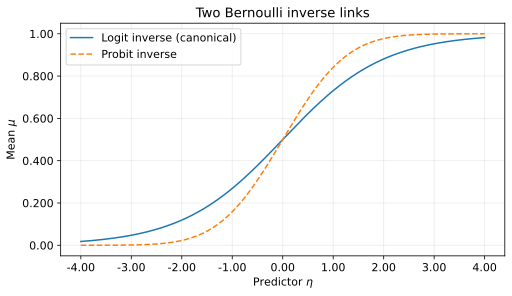

In [6]:
eta = np.linspace(-4, 4, 400)
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
ax.plot(eta, expit(eta), label="Logit inverse (canonical)")
ax.plot(eta, ndtr(eta), linestyle="--", label="Probit inverse")
ax.set(xlabel=r"Predictor $\eta$", ylabel=r"Mean $\mu$", title="Two Bernoulli inverse links")
ax.legend()
save_figure(fig, "link_comparison.svg")

## 結論

この記事では、正準リンクを平均と自然パラメータの関係から導き、代表的な3分布とPythonによる推定例を確認した。

正準リンクは$g_{\mathrm c}=(b')^{-1}$であり、線形予測子と自然パラメータを一致させる。正規分布では恒等関数、ベルヌーイ分布ではロジット、ポアソン分布では対数となる。尤度の微分が簡単になる一方、データに適したリンクかどうかは別に判断する必要がある。

参考文献：Nathaniel E. Helwig, [Generalized Linear Models in R](https://users.stat.umn.edu/~helwig/notes/generalized-linear-models.html), §1；Andrew Ng・Tengyu Ma, [CS229 Lecture Notes](https://cs229.stanford.edu/notes2022fall/main_notes.pdf), Chapter 3.